This test is on
1. i.i.d. rayleigh fading channel
2. 4*4 MIMO channel
3. 1000 symbols per channel
4. total of 1000 channels


In [1]:
"""
DONT RUN THIS CODE BLOCK WHEN USING LOCAL COMPUTER
THIS IS ONLY FOR GOOGLE COLAB
"""
!cd /content
!rm -rf EE_MIMO_PROJECT
!git clone https://github.com/billlllllllly/EE_MIMO_PROJECT.git
# load the whole repo
%cd EE_MIMO_PROJECT
%pip install -r requirements.txt
# change the dir
!ls
# just for checking that the current folder is correct

Cloning into 'EE_MIMO_PROJECT'...
remote: Enumerating objects: 343, done.
remote: Counting objects: 100% (343/343), done.
remote: Compressing objects: 100% (242/242), done.
remote: Total 343 (delta 141), reused 230 (delta 84), pack-reused 0 (from 0)
Receiving objects: 100% (343/343), 7.16 MiB | 9.43 MiB/s, done.
Resolving deltas: 100% (141/141), done.
/content/EE_MIMO_PROJECT
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.5/8.5 MB 66.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 128.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.6/62.6 MB 44.6 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 97.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 151.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 103.3 MB/s  0:00:00
  Attempting uninstall: widgetsnbextension
    Found existing installation: widgetsnbextension 3.6.10
    Uninstalling widgetsnbextension-3.6.10:
      Successfully uninsta

In [2]:
# import models
from src.models.MAP import MAP
from src.models.MMSE import MMSE
from src.models.SIC import SIC
from src.models.partialMAP import partialMAP

models = {
    "MAP": MAP(),
    "MMSE": MMSE(),
    "QR-SIC": SIC(),
    "Partial MAP": partialMAP(verbose=False)
}

In [3]:
# mimo settings
import torch
from src.channel.rayleighfading import rayleighfading
BLOCKS = 100000
SYMBOLS_PER_CHANNEL = 1
# total of (SYMBOLS_PER_CHANNEL * BLOCKS) symbols are transmitted
NT = 4
NR = 4
SNR_DB = list(range(0, 22, 2))

def generateChannel(NR, NT):
    return rayleighfading(NR=NR, NT=NT)

qpsk = torch.tensor([-1-1j, -1+1j, 1+1j, 1-1j], dtype=torch.complex128) / 2**0.5
gray = torch.tensor([[0, 0], [1, 0], [1, 1], [0, 1]])

In [4]:
from src.channel.testbench import Testbench
bench = Testbench(models, qpsk, gray, SYMBOLS_PER_CHANNEL, SNR_DB)
csi = torch.stack([generateChannel(NR=NR, NT=NT) for _ in range(BLOCKS)])
ber, bits_per_snr = bench.run(csi)

print(f"{bits_per_snr:,} bits per SNR")
print("SNR (dB)   " + "  ".join(f"{name:>12}" for name in models))
for snr, row in zip(SNR_DB, ber):
    print(f"{snr:8g}   " + "  ".join(f"{value:12.4g}" for value in row))

串流輸出內容已截斷至最後 5000 行。
current running csi[95012]
current running csi[95013]
current running csi[95014]
current running csi[95015]
current running csi[95016]
current running csi[95017]
current running csi[95018]
current running csi[95019]
current running csi[95020]
current running csi[95021]
current running csi[95022]
current running csi[95023]
current running csi[95024]
current running csi[95025]
current running csi[95026]
current running csi[95027]
current running csi[95028]
current running csi[95029]
current running csi[95030]
current running csi[95031]
current running csi[95032]
current running csi[95033]
current running csi[95034]
current running csi[95035]
current running csi[95036]
current running csi[95037]
current running csi[95038]
current running csi[95039]
current running csi[95040]
current running csi[95041]
current running csi[95042]
current running csi[95043]
current running csi[95044]
current running csi[95045]
current running csi[95046]
current running csi[95047]
current

Downward triangles: zero observed errors, shown at 1 / bits per SNR.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

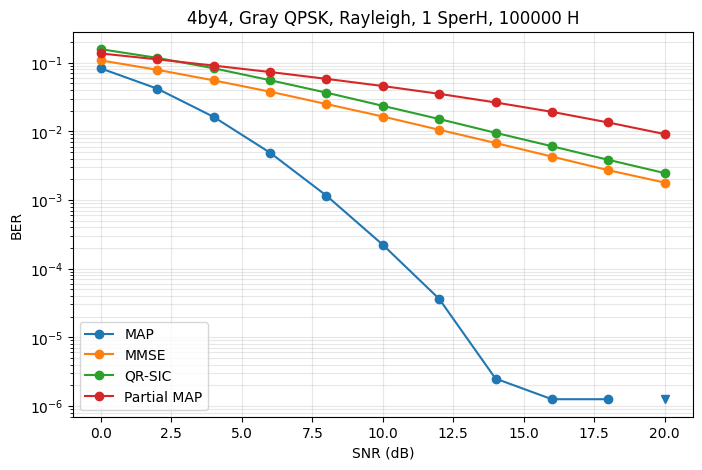

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from google.colab import files

snr_db = np.asarray(SNR_DB)
fig, ax = plt.subplots(figsize=(8, 5))

for j, name in enumerate(models):
    points = ber[:, j]
    line, = ax.semilogy(
        snr_db, np.where(points > 0, points, np.nan), "o-", label=name
    )

    zero = points == 0
    if zero.any():
        ax.semilogy(
            snr_db[zero],
            np.full(zero.sum(), 1 / bits_per_snr),
            "v",
            color=line.get_color(),
        )

TITLE = f"{NT}by{NR}, Gray QPSK, Rayleigh, {SYMBOLS_PER_CHANNEL} SperH, {BLOCKS} H"
ax.set(xlabel="SNR (dB)", ylabel="BER",
       title=TITLE)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
print("Downward triangles: zero observed errors, shown at 1 / bits per SNR.")

plt.savefig(f'{TITLE}.png', dpi=300, bbox_inches='tight')
files.download(f'{TITLE}.png')

plt.show()